## Homework 6 Problem 2 <br>
Filippa Mudsam

**part (c)**

In [52]:
import csv
import numpy as np
import matplotlib.pyplot as plt

In [53]:
w  = 1

games = []
with open('big12.csv') as f:
    for row in csv.DictReader(f):
        games.append(row)

teams = []
for g in games:
    if g['home'] not in teams:
        teams.append(g['home'])
    if g['away'] not in teams:
        teams.append(g['away'])
teams.sort()
m= len(teams)

In [54]:
def h(S,T):
    x = (S + 1) / (S + T + 2)
    return 1/2 + 1/2*np.sign(x - 1/2)*np.sqrt(abs(2*x -1))

In [55]:
G = np.zeros((m,m))
n = np.zeros(m)

In [56]:
for g in games:
    if g['season'] == '2026' and g['completed'] == '1' and g['date'] < '2026-10-10':
        i = teams.index(g['home'])
        j = teams.index(g['away'])

        S = int(g['home_pts'])
        T = int(g['away_pts'])

        G[i, j] = G[i, j] + h(S, T)
        G[j, i] = G[j, i] + h(T, S)
        
        n[i] = n[i] + 1
        n[j] = n[j] + 1

In [57]:
H25 = np.zeros((m, m))
C25 = np.zeros((m, m))
wins = np.zeros(m)
played = np.zeros(m)

In [58]:
for g in games:
    if g['season'] == '2025' and g['completed'] == '1':

        i = teams.index(g['home'])
        j = teams.index(g['away'])

        S = int(g['home_pts'])
        T = int(g['away_pts'])

        H25[i, j] = H25[i, j] + h(S, T)
        H25[j, i] = H25[j, i] + h(T, S)

        C25[i, j] = C25[i, j] + 1
        C25[j, i] = C25[j, i] + 1
        
        if S > T:
            wins[i] = wins[i] + 1
        else:
            wins[j] = wins[j] + 1
        played[i] = played[i] + 1
        played[j] = played[j] + 1

First prior, flat

In [59]:
pi_flat = np.zeros((m,m))
for i in range(m):
    for j in range(m):
        pi_flat[i,j] = 1/2

second prior

In [60]:
pi_last = np.zeros((m,m))
for i in range(m):
    for j in range(m):
        if C25[i,j] > 0:
            pi_last[i,j] = H25[i,j]/C25[i,j]
        else:
            pi_last[i,j] = 1/2

prior 3

In [61]:
s = (wins + 1)/(played + 2)
Pi_own = np.zeros((m, m))

for i in range(m):
    
    for j in range(m):
        Pi_own[i, j] = s[i]/(s[i] + s[j])

In [62]:
priors = [pi_flat, pi_last, Pi_own]
names = ['flat', 'last season', '2025 win fraction']

In [63]:
#something wrong with n -> fixed
print(np.shape(G[0, 1]), np.shape(Pi[0, 1]), np.shape(n[0]), np.shape(w))

() () () ()


BYU
Oklahoma State
Arizona
Houston
Utah


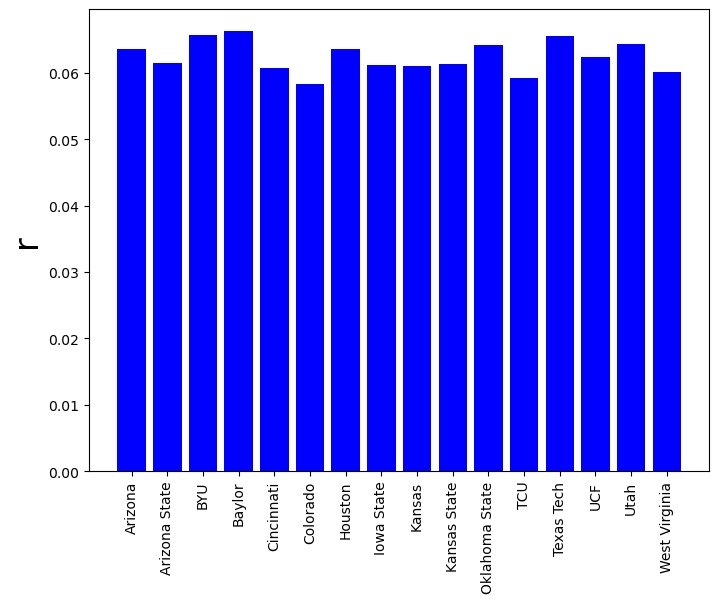

BYU
UCF
Arizona
Houston
Utah


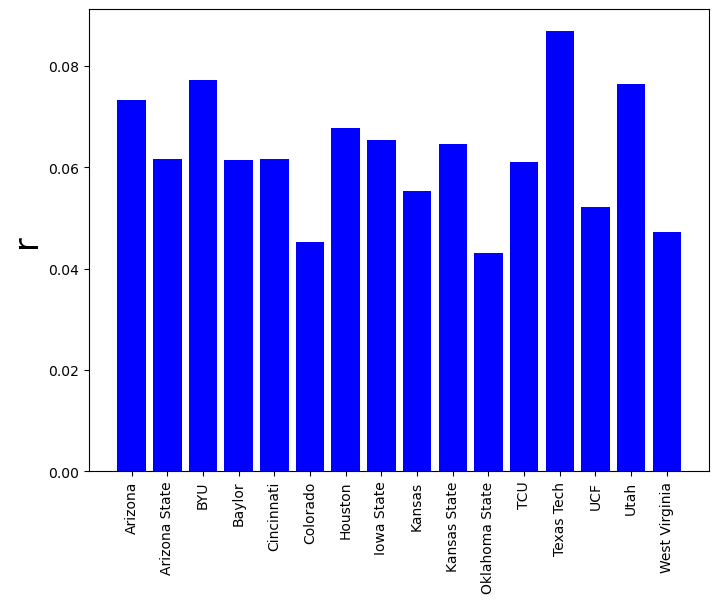

BYU
UCF
Arizona
Houston
Utah


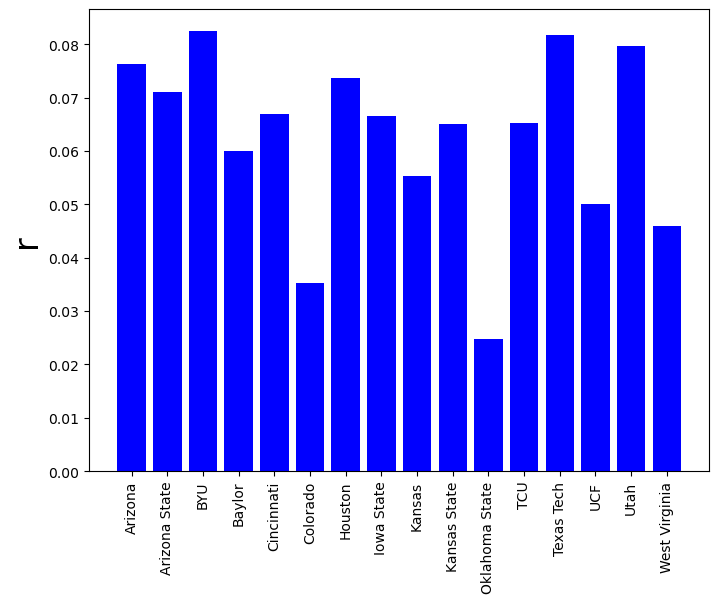

In [64]:
for k in range(3):
    Pi = priors[k]

    A = np.zeros((m, m))
    for i in range(m):
        for j in range(m):
            if i != j:
                A[i, j] = (G[i, j] + w*Pi[i, j])/(n[i] + w*(m-1))

    r = np.ones(m)/m
    for it in range(1000):
        r = A @ r
        r = r/np.sum(r)
    lambda_ = np.sum(A @ r) 

    lambda_ = np.sort(np.abs(np.linalg.eigvals(A)))
    lambda_2 = lambda_[-2]

    #predicting oct10-11 games
    correct = 0
    total = 0
    for g in games:
         if g['season'] == '2026' and (g['date'] == '2026-10-10' or g['date'] == '2026-10-11'):
            i = teams.index(g['home'])
            j = teams.index(g['away'])
            if r[i] > r[j]:
                pick = g['home']
            else:
                pick = g['away']
 
            if g['completed'] == '1':
                if int(g['home_pts']) > int(g['away_pts']):
                    winner = g['home']
                else:
                    winner = g['away']
                if pick == winner:
                    correct = correct + 1
                total = total + 1
                print(winner)
            else:
                print((pick))

    plt.figure(k+1, figsize=(8, 6))
    plt.bar(np.arange(m), r, color='b')
    plt.xticks(np.arange(m), teams, rotation=90)
    plt.ylabel('r', fontsize=24)
    plt.show()
 

 